# Sucesiones, Taylor y dinámica discreta

## Objetivo
Reconocer convergencia de una serie y estabilidad de un modelo recurrente.

**Datos:** ejemplos analíticos o simulaciones didácticas; no representan clientes ni estimaciones de mercado.

## Preparación
Python 3.11 o posterior, NumPy, SciPy y Matplotlib. Todo se genera aquí; no necesita internet. Lee la fórmula y predice el resultado antes de ejecutar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#285A8E','#C77C36','#687D45'])})
rng = np.random.default_rng(20261025)


## 1. Sumar una serie geométrica

Para $|r|<1$, $S_n=\sum_{k=0}^{n}r^k=(1-r^{n+1})/(1-r)$ converge a $1/(1-r)$. El error exacto es $|r|^{n+1}/|1-r|$. Con r=0.8 la convergencia es más lenta que con r=0.3.

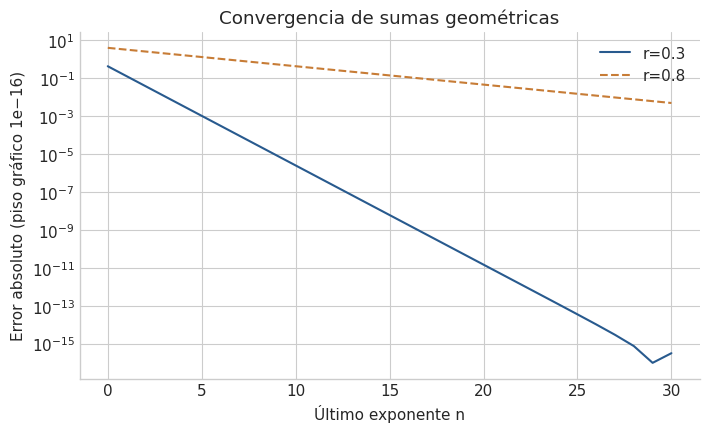

In [2]:
n=np.arange(31)
fig,ax=plt.subplots()
for r,estilo in [(.3,'-'),(.8,'--')]:
    sumas=np.cumsum(r**n)
    ax.semilogy(n,np.abs(sumas-1/(1-r))+1e-16,estilo,label=f'r={r}')
ax.set(xlabel='Último exponente n',ylabel='Error absoluto (piso gráfico 1e−16)',title='Convergencia de sumas geométricas')
ax.legend(); plt.show()

**Lectura del resultado.** Cuando r se acerca a 1 hacen falta más términos. El piso añadido evita logaritmos de cero en la figura; no forma parte de la fórmula matemática.

## 2. Taylor es una aproximación local

Para $e^x$, el polinomio de grado 2 alrededor de 0 es $1+x+x^2/2$. En $|x|\le a$, el resto está acotado por $e^a|x|^3/6$. Una aproximación útil cerca de cero puede fallar lejos.

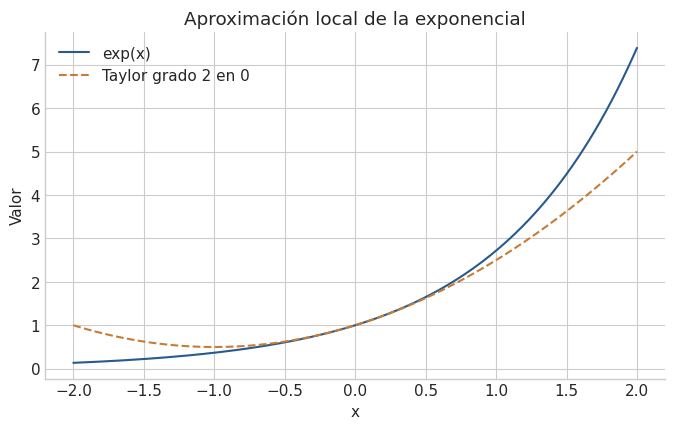

Error en x=0.1: 0.0001709180756477302


In [3]:
x=np.linspace(-2,2,201)
p=1+x+x*x/2
fig,ax=plt.subplots()
ax.plot(x,np.exp(x),label='exp(x)'); ax.plot(x,p,'--',label='Taylor grado 2 en 0')
ax.set(xlabel='x',ylabel='Valor',title='Aproximación local de la exponencial'); ax.legend(); plt.show()
print('Error en x=0.1:',abs(np.exp(.1)-(1+.1+.1**2/2)))

**Lectura del resultado.** El acuerdo es estrecho cerca del centro 0 y empeora al alejarse. El orden del polinomio y el intervalo importan.

## 3. Estabilidad de una recurrencia

En $z_{t+1}=a+bz_t$, el equilibrio es $z^*=a/(1-b)$ si $b\ne1$. Restar el equilibrio da $z_{t+1}-z^*=b(z_t-z^*)$, así que se converge si $|b|<1$. Un b negativo genera oscilaciones.

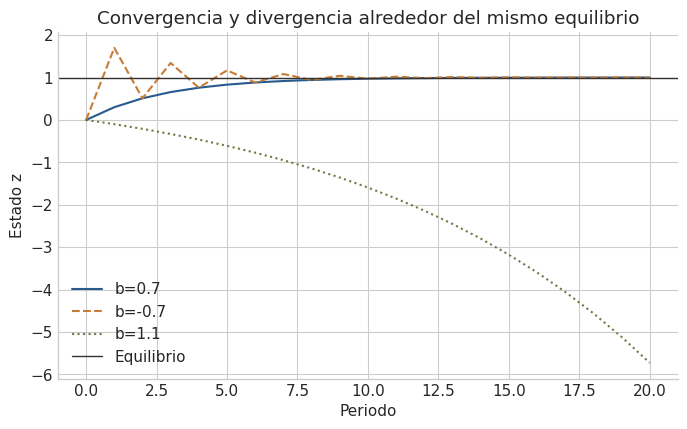

In [4]:
fig,ax=plt.subplots()
for b,estilo in [(.7,'-'),(-.7,'--'),(1.1,':')]:
    # Elegimos a=1-b para que todos tengan equilibrio 1.
    a=1-b
    trayectoria=[0.]
    for _ in range(20): trayectoria.append(a+b*trayectoria[-1])
    ax.plot(trayectoria,estilo,label=f'b={b}')
ax.axhline(1,color='#333333',lw=1,label='Equilibrio')
ax.set(xlabel='Periodo',ylabel='Estado z',title='Convergencia y divergencia alrededor del mismo equilibrio')
ax.legend(); plt.show()

**Lectura del resultado.** Con b=0.7 converge sin alternancia; con -0.7 oscila y converge; con 1.1 se aleja. Tener equilibrio no garantiza estabilidad.

## Practica antes de ver la solución

Para zₜ₊₁=2+0.5zₜ, z₀=0, encuentra equilibrio y una fórmula para zₜ.

In [5]:
# Escribe aquí tu razonamiento y tu cálculo.


## Solución razonada

El equilibrio es 4. Restando 4 resulta zₜ−4=0.5ᵗ(0−4), así que zₜ=4(1−0.5ᵗ).

## Comprobaciones

Estas pruebas contrastan identidades, referencias analíticas y tolerancias; no prueban teoremas ni validan modelos reales.

In [6]:
r=.8
assert np.isclose(np.sum(r**np.arange(11)),(1-r**11)/(1-r))
assert abs(np.exp(.1)-(1+.1+.1**2/2)) <= np.exp(.1)*.1**3/6
z=0.
for t in range(1,11):
    z=2+.5*z
    assert np.isclose(z,4*(1-.5**t))
print('Serie, cota de Taylor y recurrencia: OK')

Serie, cota de Taylor y recurrencia: OK


## Siguiente paso

Cambia un parámetro, anticipa el efecto y explica por qué ocurre. Vuelve a ejecutar desde un kernel limpio. Consulta el índice del curso para la lección teórica relacionada.